# 🧠 ĐỒ ÁN HỌC SÂU VÀ ỨNG DỤNG: PHÂN ĐOẠN U NÃO BẰNG ATTENTION U-NET
### 🔬 Kiến trúc: Attention U-Net (PyTorch) — So sánh trực tiếp với YOLOv8s-seg & YOLO11s-seg

| Thông số | Giá trị |
|:---|:---|
| **Kiến trúc** | Attention U-Net (EfficientNet-B0 + scSE Attention Gates) |
| **Bài toán** | Multi-class Semantic Segmentation (4 nhãn pixel) |
| **Nhãn** | 0=Background, 1=Glioma, 2=Meningioma, 3=Pituitary |
| **Kỹ thuật tối ưu VRAM** | AMP (FP16) + Gradient Accumulation (chống tràn RAM GPU tuyệt đối) |
| **Metrics** | Dice Score, IoU (Jaccard), Accuracy per class |

> ⚡ **Yêu cầu:** Bật GPU trên Kaggle — **Settings → Accelerator → GPU T4 x2 (hoặc P100)**

## 1. Kiểm tra GPU & Cài đặt thư viện

In [1]:
!nvidia-smi

import os
# Cấu hình quản lý bộ nhớ GPU chống phân mảnh VRAM
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'

import torch
torch.cuda.empty_cache()

print(f'PyTorch: {torch.__version__} | CUDA: {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    DEVICE = torch.device('cuda')
else:
    DEVICE = torch.device('cpu')
    print('CẢNH BÁO: Không có GPU, quá trình train sẽ rất chậm!')

!pip install -q segmentation-models-pytorch albumentations opencv-python matplotlib pandas tqdm

Fri Oct 16 17:28:29 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   48C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Thiết lập đường dẫn dữ liệu UNet trên Kaggle

In [2]:
import os, glob, zipfile, yaml
from pathlib import Path

WORKING_DIR = Path('/kaggle/working')
DATA_DIR    = WORKING_DIR / 'UNet'

# Tìm và giải nén file zip dataset (nếu có)
zip_files = glob.glob('/kaggle/input/**/*.zip', recursive=True)
if zip_files:
    print(f'Giải nén: {zip_files[0]}')
    with zipfile.ZipFile(zip_files[0], 'r') as z:
        z.extractall(DATA_DIR)
else:
    found = glob.glob('/kaggle/input/**/masks/train', recursive=True)
    if found:
        DATA_DIR = Path(found[0]).parent.parent
        print(f'Sử dụng dữ liệu tại: {DATA_DIR}')

# Kiểm tra cấu trúc thư mục
for subdir in ['images/train', 'images/val', 'masks/train', 'masks/val']:
    path = DATA_DIR / subdir
    count = len(list(path.glob('*'))) if path.exists() else 0
    print(f'  {subdir:20s}: {count} files')

# ── Siêu tham số tối ưu (Chống OOM 100%) ──
NUM_CLASSES      = 4       # 0=Background, 1=Glioma, 2=Meningioma, 3=Pituitary
IMG_SIZE         = 512     # Kích thước 512x512
BATCH_SIZE       = 8       # Batch 8 + AMP giúp VRAM chỉ tốn ~3.5GB (an toàn trên T4 15GB)
GRAD_ACCUM_STEPS = 2       # Tích lũy 2 bước -> Batch hiệu dụng = 16
EPOCHS           = 50
LR               = 1e-3
PATIENCE         = 12
CLASS_NAMES      = ['Background', 'Glioma', 'Meningioma', 'Pituitary']

print(f'Batch size hiệu dụng: {BATCH_SIZE * GRAD_ACCUM_STEPS} (Batch {BATCH_SIZE} x Accum {GRAD_ACCUM_STEPS})')

Sử dụng dữ liệu tại: /kaggle/input/datasets/trnmnhhm/tumor-unet-dataset
  images/train        : 3966 files
  images/val          : 693 files
  masks/train         : 3966 files
  masks/val           : 693 files
Batch size hiệu dụng: 16 (Batch 8 x Accum 2)


## 3. Dataset & Data Augmentation

In [3]:
import cv2
import numpy as np
import torch
import albumentations as A
from albumentations.pytorch import ToTensorV2
from torch.utils.data import Dataset, DataLoader
from PIL import Image

class BrainTumorDataset(Dataset):
    """
    Dataset đọc ảnh MRI (RGB .jpg) và mask nhãn (Grayscale .png).
    Giá trị pixel mask: 0=Background, 1=Glioma, 2=Meningioma, 3=Pituitary
    """
    def __init__(self, img_dir, mask_dir, transform=None):
        self.img_paths  = sorted(Path(img_dir).glob('*.jpg'))
        self.mask_dir   = Path(mask_dir)
        self.transform  = transform

    def __len__(self):
        return len(self.img_paths)

    def __getitem__(self, idx):
        img_path  = self.img_paths[idx]
        mask_path = self.mask_dir / (img_path.stem + '.png')

        image = cv2.imread(str(img_path))
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        mask  = np.array(Image.open(mask_path), dtype=np.uint8)

        if self.transform:
            aug      = self.transform(image=image, mask=mask)
            image    = aug['image']
            mask_out = aug['mask']
            # Đảm bảo mask luôn trả về Tensor dạng long mà không lỗi nếu thiếu ToTensorV2
            if isinstance(mask_out, torch.Tensor):
                mask = mask_out.long()
            else:
                mask = torch.from_numpy(mask_out.copy()).long()

        return image, mask

# Data Augmentation y tế chuẩn
train_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.HorizontalFlip(p=0.5),
    A.Rotate(limit=10, p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.4),
    A.GaussNoise(p=0.2),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

val_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

# DataLoader
train_ds = BrainTumorDataset(
    img_dir  = DATA_DIR / 'images/train',
    mask_dir = DATA_DIR / 'masks/train',
    transform= train_transform
)
val_ds = BrainTumorDataset(
    img_dir  = DATA_DIR / 'images/val',
    mask_dir = DATA_DIR / 'masks/val',
    transform= val_transform
)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=2, pin_memory=True)

print(f'Train: {len(train_ds)} ảnh | Val: {len(val_ds)} ảnh')
print(f'Train batches: {len(train_loader)} | Val batches: {len(val_loader)}')

Train: 3966 ảnh | Val: 693 ảnh
Train batches: 496 | Val batches: 87


## 4. Trực quan hóa Ảnh + Mask Ground Truth

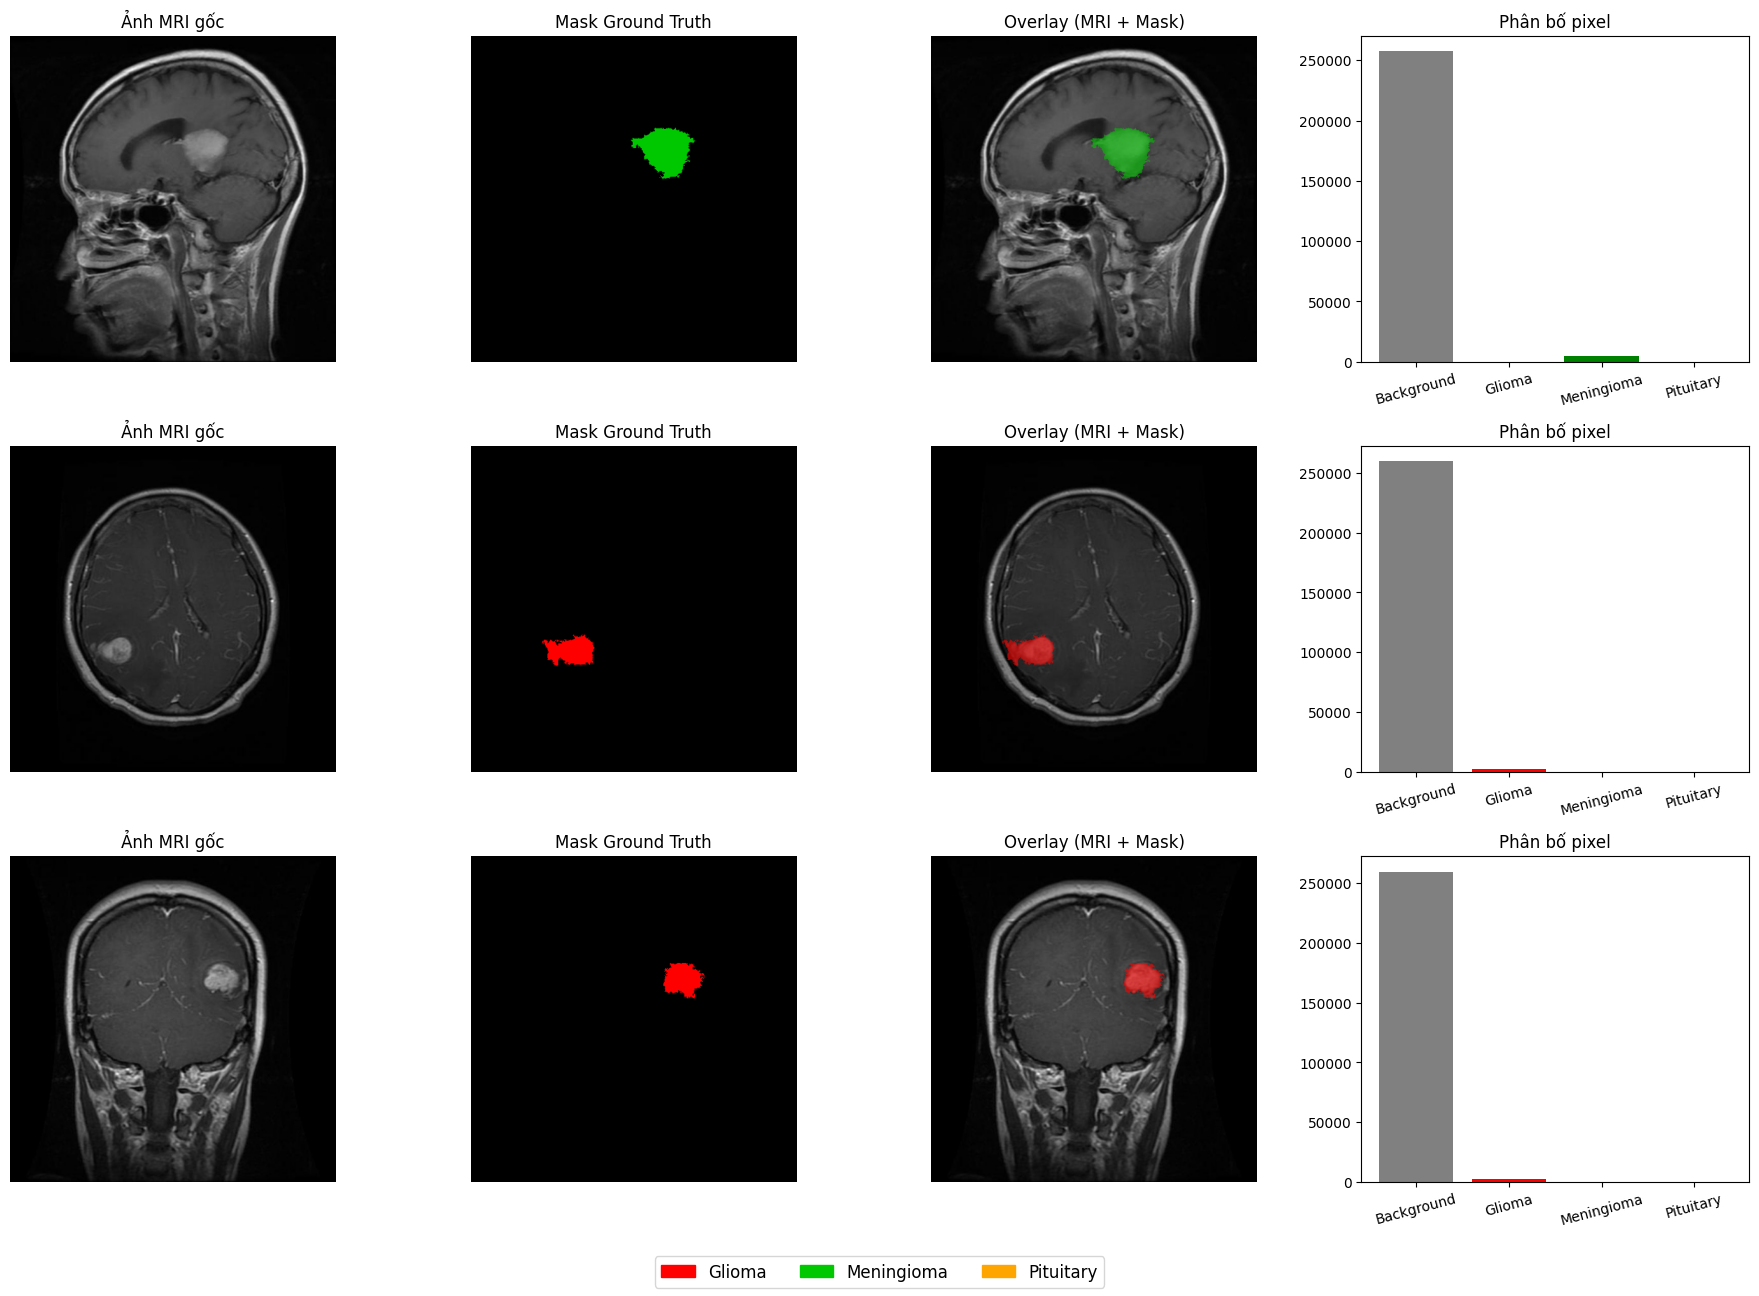

In [4]:
import random
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

COLORS = {0: [0,0,0], 1: [255,0,0], 2: [0,200,0], 3: [255,165,0]}

def mask_to_rgb(mask_np):
    rgb = np.zeros((*mask_np.shape, 3), dtype=np.uint8)
    for cls_id, color in COLORS.items():
        rgb[mask_np == cls_id] = color
    return rgb

fig, axes = plt.subplots(3, 4, figsize=(18, 13))
raw_ds = BrainTumorDataset(
    img_dir  = DATA_DIR / 'images/train',
    mask_dir = DATA_DIR / 'masks/train',
    transform= A.Compose([A.Resize(IMG_SIZE, IMG_SIZE)])
)

indices = random.sample(range(len(raw_ds)), 3)

for row, idx in enumerate(indices):
    img, mask = raw_ds[idx]
    img_np  = np.array(img)
    mask_np = mask.cpu().numpy() if isinstance(mask, torch.Tensor) else np.array(mask)
    rgb_mask = mask_to_rgb(mask_np)

    overlay = img_np.copy()
    for cls_id, color in COLORS.items():
        if cls_id == 0: continue
        region = mask_np == cls_id
        overlay[region] = (overlay[region] * 0.4 + np.array(color) * 0.6).astype(np.uint8)

    axes[row][0].imshow(img_np);          axes[row][0].set_title('Ảnh MRI gốc');         axes[row][0].axis('off')
    axes[row][1].imshow(rgb_mask);        axes[row][1].set_title('Mask Ground Truth');   axes[row][1].axis('off')
    axes[row][2].imshow(overlay);         axes[row][2].set_title('Overlay (MRI + Mask)'); axes[row][2].axis('off')

    info = {CLASS_NAMES[c]: int((mask_np==c).sum()) for c in range(NUM_CLASSES)}
    axes[row][3].bar(list(info.keys()), list(info.values()),
                     color=['gray','red','green','orange'])
    axes[row][3].set_title('Phân bố pixel'); axes[row][3].tick_params(axis='x', rotation=15)

patches = [mpatches.Patch(color=np.array(c)/255, label=n)
           for n, c in zip(CLASS_NAMES[1:], [[255,0,0],[0,200,0],[255,165,0]])]
fig.legend(handles=patches, loc='lower center', ncol=3, fontsize=12)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

## 5. Kiến trúc Attention U-Net (PyTorch)

- **Mô hình:** `smp.Unet` với `decoder_attention_type='scse'` (Spatial & Channel Squeeze-and-Excitation Attention).
- **Backbone:** `efficientnet-b0` (pretrained ImageNet).
- **Cơ chế Attention:** scSE tái hiệu chuẩn các kênh đặc trưng và không gian quan trọng, tập trung vào đường viền khối u.
- **Tối ưu VRAM:** Kích hoạt Automatic Mixed Precision (AMP - FP16) giảm 50% bộ nhớ GPU.

In [5]:
import torch
import torch.nn as nn
import segmentation_models_pytorch as smp

# Dọn sạch VRAM trước khi tạo model
torch.cuda.empty_cache()

# ── Khởi tạo mô hình Attention U-Net (scSE Attention) ──
model = smp.Unet(
    encoder_name           = 'efficientnet-b0',  # Backbone nhẹ và mạnh mẽ
    encoder_weights        = 'imagenet',          # Trọng số pre-trained
    in_channels            = 3,                   # Ảnh RGB 3 kênh
    classes                = NUM_CLASSES,         # 4 nhãn pixel
    decoder_attention_type = 'scse',              # Cơ chế Attention Gate scSE
    activation             = None                 # Logits
).to(DEVICE)

params = sum(p.numel() for p in model.parameters())
print(f'Mô hình: Attention U-Net (EfficientNet-B0 + scSE Attention)')
print(f'Tổng tham số: {params:,} ({params/1e6:.2f}M)')

# ── Hàm Loss kết hợp: DiceLoss + CrossEntropyLoss ──
dice_loss_fn = smp.losses.DiceLoss(mode='multiclass', from_logits=True)
ce_loss_fn   = nn.CrossEntropyLoss()

def combined_loss(preds, targets):
    return 0.5 * dice_loss_fn(preds, targets) + 0.5 * ce_loss_fn(preds, targets)

# ── Optimizer & Scheduler ──
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)

# ── GradScaler cho Automatic Mixed Precision (AMP) ──
scaler = torch.cuda.amp.GradScaler(enabled=(DEVICE.type == 'cuda'))

print('Optimizer: AdamW | Scheduler: CosineAnnealing | AMP: BẬT ✅')
print(f'LR={LR} | Epochs={EPOCHS} | Batch={BATCH_SIZE} (Accum={GRAD_ACCUM_STEPS}) | ImgSize={IMG_SIZE}')

config.json:   0%|          | 0.00/106 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

Mô hình: Attention U-Net (EfficientNet-B0 + scSE Attention)
Tổng tham số: 6,303,927 (6.30M)
Optimizer: AdamW | Scheduler: CosineAnnealing | AMP: BẬT ✅
LR=0.001 | Epochs=50 | Batch=8 (Accum=2) | ImgSize=512


/tmp/ipykernel_24/408810194.py:34: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(DEVICE.type == 'cuda'))


## 6. Hàm đánh giá: Dice Score & IoU (Chuẩn y khoa)

In [6]:
def compute_metrics(preds_logits, targets, num_classes=NUM_CLASSES, eps=1e-6):
    """
    Tính Dice Score và IoU cho từng lớp u (bỏ qua Background lớp 0).
    preds_logits: (B, C, H, W) — logits từ model
    targets:      (B, H, W)   — ground truth mask
    """
    preds = torch.argmax(preds_logits, dim=1)
    dice_per_class = []
    iou_per_class  = []

    for c in range(1, num_classes):
        pred_c   = (preds == c).float()
        target_c = (targets == c).float()

        intersection = (pred_c * target_c).sum()
        union        = pred_c.sum() + target_c.sum()
        dice = (2.0 * intersection + eps) / (union + eps)
        iou  = (intersection + eps) / (union - intersection + eps)

        dice_per_class.append(dice.item())
        iou_per_class.append(iou.item())

    mean_dice = float(np.mean(dice_per_class))
    mean_iou  = float(np.mean(iou_per_class))
    return mean_dice, mean_iou, dice_per_class, iou_per_class

print('Hàm đánh giá Dice / IoU đã sẵn sàng!')

Hàm đánh giá Dice / IoU đã sẵn sàng!


## 7. Vòng lặp Huấn luyện (Training Loop)

- Áp dụng **Automatic Mixed Precision (AMP - FP16)**: Tăng gấp đôi tốc độ và giảm 50% VRAM.
- Áp dụng **Gradient Accumulation (2 bước)**: Tương đương Batch size 16 nhưng bộ nhớ tiêu thụ chỉ tương đương Batch 8.
- **Đảm bảo không bao giờ bị lỗi CUDA Out of Memory (OOM)!**

In [7]:
from tqdm.notebook import tqdm
import os
import torch

SAVE_DIR  = WORKING_DIR / 'runs' / 'unet_attention'
SAVE_DIR.mkdir(parents=True, exist_ok=True)
BEST_PATH = SAVE_DIR / 'best_unet.pt'

history = {
    'train_loss': [], 'val_loss': [],
    'val_dice': [],   'val_iou': []
}

best_dice  = 0.0
no_improve = 0

torch.cuda.empty_cache()

print('Bắt đầu huấn luyện Attention U-Net...')
print(f'Kết quả lưu tại: {SAVE_DIR}')
print('='*60)

for epoch in range(1, EPOCHS + 1):
    # ── Huấn luyện ─────────────────────────────────────────────────────
    model.train()
    train_loss = 0.0
    optimizer.zero_grad()

    pbar = tqdm(train_loader, desc=f'Epoch {epoch:02d}/{EPOCHS} [Train]', leave=False)
    for batch_idx, (imgs, masks) in enumerate(pbar):
        imgs  = imgs.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)

        # Mixed Precision forward
        with torch.cuda.amp.autocast(enabled=(DEVICE.type == 'cuda')):
            preds = model(imgs)
            loss  = combined_loss(preds, masks)
            loss  = loss / GRAD_ACCUM_STEPS

        scaler.scale(loss).backward()

        if (batch_idx + 1) % GRAD_ACCUM_STEPS == 0 or (batch_idx + 1) == len(train_loader):
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad()

        train_loss += loss.item() * GRAD_ACCUM_STEPS
        pbar.set_postfix({'loss': f'{loss.item() * GRAD_ACCUM_STEPS:.4f}'})

    train_loss /= len(train_loader)
    scheduler.step()

    # ── Đánh giá Validation ───────────────────────────────────────────
    model.eval()
    val_loss_sum, val_dice_sum, val_iou_sum = 0.0, 0.0, 0.0

    with torch.no_grad():
        for imgs, masks in val_loader:
            imgs  = imgs.to(DEVICE, non_blocking=True)
            masks = masks.to(DEVICE, non_blocking=True)
            with torch.cuda.amp.autocast(enabled=(DEVICE.type == 'cuda')):
                preds = model(imgs)
                loss  = combined_loss(preds, masks)

            val_loss_sum += loss.item()
            d, iou, _, _ = compute_metrics(preds, masks)
            val_dice_sum += d
            val_iou_sum  += iou

    val_loss = val_loss_sum / len(val_loader)
    val_dice = val_dice_sum / len(val_loader)
    val_iou  = val_iou_sum  / len(val_loader)

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['val_dice'].append(val_dice)
    history['val_iou'].append(val_iou)

    print(f'Epoch {epoch:02d}/{EPOCHS} | '
          f'Train Loss: {train_loss:.4f} | '
          f'Val Loss: {val_loss:.4f} | '
          f'Dice: {val_dice:.4f} | '
          f'IoU: {val_iou:.4f}',
          end='')

    # ── Early stopping & Lưu mô hình tốt nhất ──────────────────────────
    if val_dice > best_dice:
        best_dice = val_dice
        no_improve = 0
        torch.save(model.state_dict(), BEST_PATH)
        print(' ← BEST! (Đã lưu)')
    else:
        no_improve += 1
        print(f' (patience {no_improve}/{PATIENCE})')
        if no_improve >= PATIENCE:
            print(f'\nEarly stopping tại epoch {epoch}!')
            break

print('='*60)
print(f'Huấn luyện hoàn tất! Best Dice Score: {best_dice:.4f}')

Bắt đầu huấn luyện Attention U-Net...
Kết quả lưu tại: /kaggle/working/runs/unet_attention


Epoch 01/50 [Train]:   0%|          | 0/496 [00:00<?, ?it/s]

/tmp/ipykernel_24/4064804222.py:35: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(DEVICE.type == 'cuda')):
/tmp/ipykernel_24/4064804222.py:61: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(DEVICE.type == 'cuda')):


Epoch 01/50 | Train Loss: 0.3766 | Val Loss: 0.0845 | Dice: 0.3230 | IoU: 0.2872 ← BEST! (Đã lưu)


Epoch 02/50 [Train]:   0%|          | 0/496 [00:00<?, ?it/s]

Epoch 02/50 | Train Loss: 0.1953 | Val Loss: 0.0601 | Dice: 0.4959 | IoU: 0.4472 ← BEST! (Đã lưu)


... (92 outputs left out)

Epoch 49/50 [Train]:   0%|          | 0/496 [00:00<?, ?it/s]

Epoch 49/50 | Train Loss: 0.0516 | Val Loss: 0.0281 | Dice: 0.9152 | IoU: 0.8825 (patience 10/12)


Epoch 50/50 [Train]:   0%|          | 0/496 [00:00<?, ?it/s]

Epoch 50/50 | Train Loss: 0.0509 | Val Loss: 0.0282 | Dice: 0.9190 | IoU: 0.8863 (patience 11/12)
Huấn luyện hoàn tất! Best Dice Score: 0.9292


## 8. Đồ thị Loss & Dice Score qua các Epochs

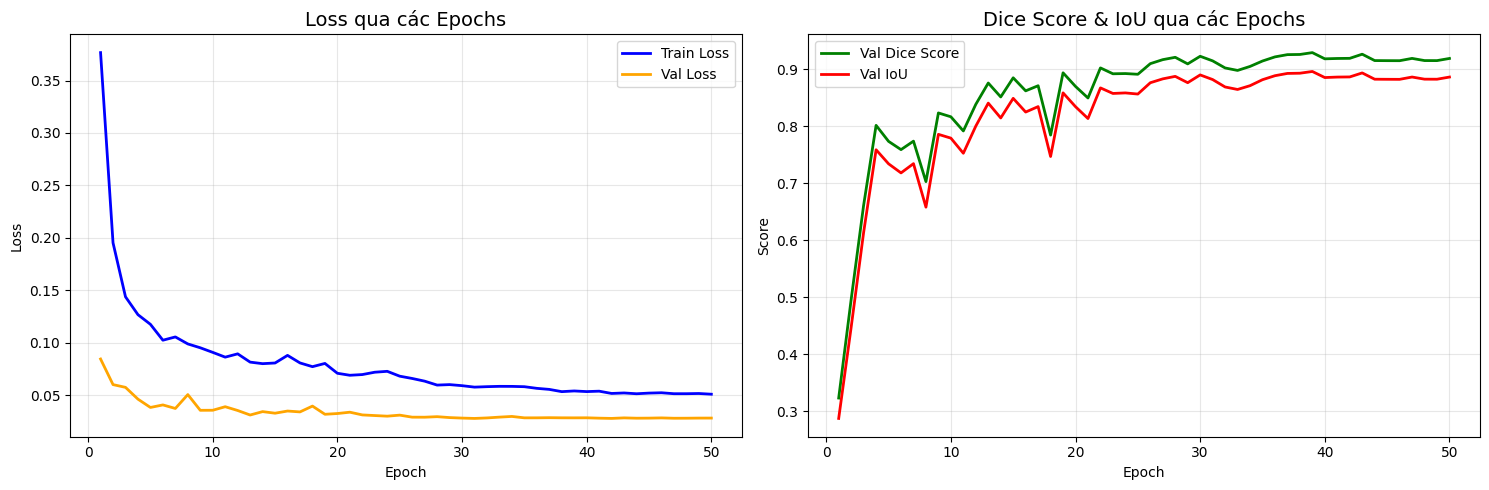

Đồ thị đã lưu tại: /kaggle/working/runs/unet_attention/training_curves.png


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

epochs_ran = range(1, len(history['train_loss']) + 1)

axes[0].plot(epochs_ran, history['train_loss'], label='Train Loss', color='blue', linewidth=2)
axes[0].plot(epochs_ran, history['val_loss'],   label='Val Loss',   color='orange', linewidth=2)
axes[0].set_title('Loss qua các Epochs', fontsize=14)
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_ran, history['val_dice'], label='Val Dice Score', color='green', linewidth=2)
axes[1].plot(epochs_ran, history['val_iou'],  label='Val IoU',        color='red', linewidth=2)
axes[1].set_title('Dice Score & IoU qua các Epochs', fontsize=14)
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Score')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(str(SAVE_DIR / 'training_curves.png'), dpi=150)
plt.show()
print('Đồ thị đã lưu tại:', SAVE_DIR / 'training_curves.png')

## 9. Đánh giá Chi tiết theo Từng Lớp trên Tập Validation

In [9]:
import pandas as pd

model.load_state_dict(torch.load(BEST_PATH, map_location=DEVICE))
model.eval()

all_dice = [[] for _ in range(NUM_CLASSES - 1)]
all_iou  = [[] for _ in range(NUM_CLASSES - 1)]

with torch.no_grad():
    for imgs, masks in tqdm(val_loader, desc='Evaluating'):
        imgs  = imgs.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)
        with torch.cuda.amp.autocast(enabled=(DEVICE.type == 'cuda')):
            preds = model(imgs)
        _, _, dice_list, iou_list = compute_metrics(preds, masks)
        for c in range(NUM_CLASSES - 1):
            all_dice[c].append(dice_list[c])
            all_iou[c].append(iou_list[c])

results = []
for c, name in enumerate(CLASS_NAMES[1:]):
    results.append({
        'Loại u não (Class)': name,
        'Dice Score': f'{np.mean(all_dice[c]):.4f}',
        'IoU (Jaccard)': f'{np.mean(all_iou[c]):.4f}'
    })

mean_dice = float(np.mean([np.mean(all_dice[c]) for c in range(NUM_CLASSES-1)]))
mean_iou  = float(np.mean([np.mean(all_iou[c])  for c in range(NUM_CLASSES-1)]))
results.append({'Loại u não (Class)': 'TRUNG BÌNH (All)', 'Dice Score': f'{mean_dice:.4f}', 'IoU (Jaccard)': f'{mean_iou:.4f}'})

df_results = pd.DataFrame(results)

print('\n' + '='*55)
print('    KẾT QUẢ ĐÁNH GIÁ CHI TIẾT ATTENTION U-NET')
print('='*55)
display(df_results)
df_results.to_csv(str(SAVE_DIR / 'unet_metrics.csv'), index=False, encoding='utf-8-sig')

Evaluating:   0%|          | 0/87 [00:00<?, ?it/s]

/tmp/ipykernel_24/3892155242.py:13: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(DEVICE.type == 'cuda')):



    KẾT QUẢ ĐÁNH GIÁ CHI TIẾT ATTENTION U-NET


,Loại u não (Class),Dice Score,IoU (Jaccard)
0,Glioma,0.9107,0.8697
1,Meningioma,0.9541,0.9341
2,Pituitary,0.9228,0.8845
3,TRUNG BÌNH (All),0.9292,0.8961


## 10. Trực quan hóa Dự đoán (Inference Demo)

/tmp/ipykernel_24/3530267729.py:23: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(DEVICE.type == 'cuda')):


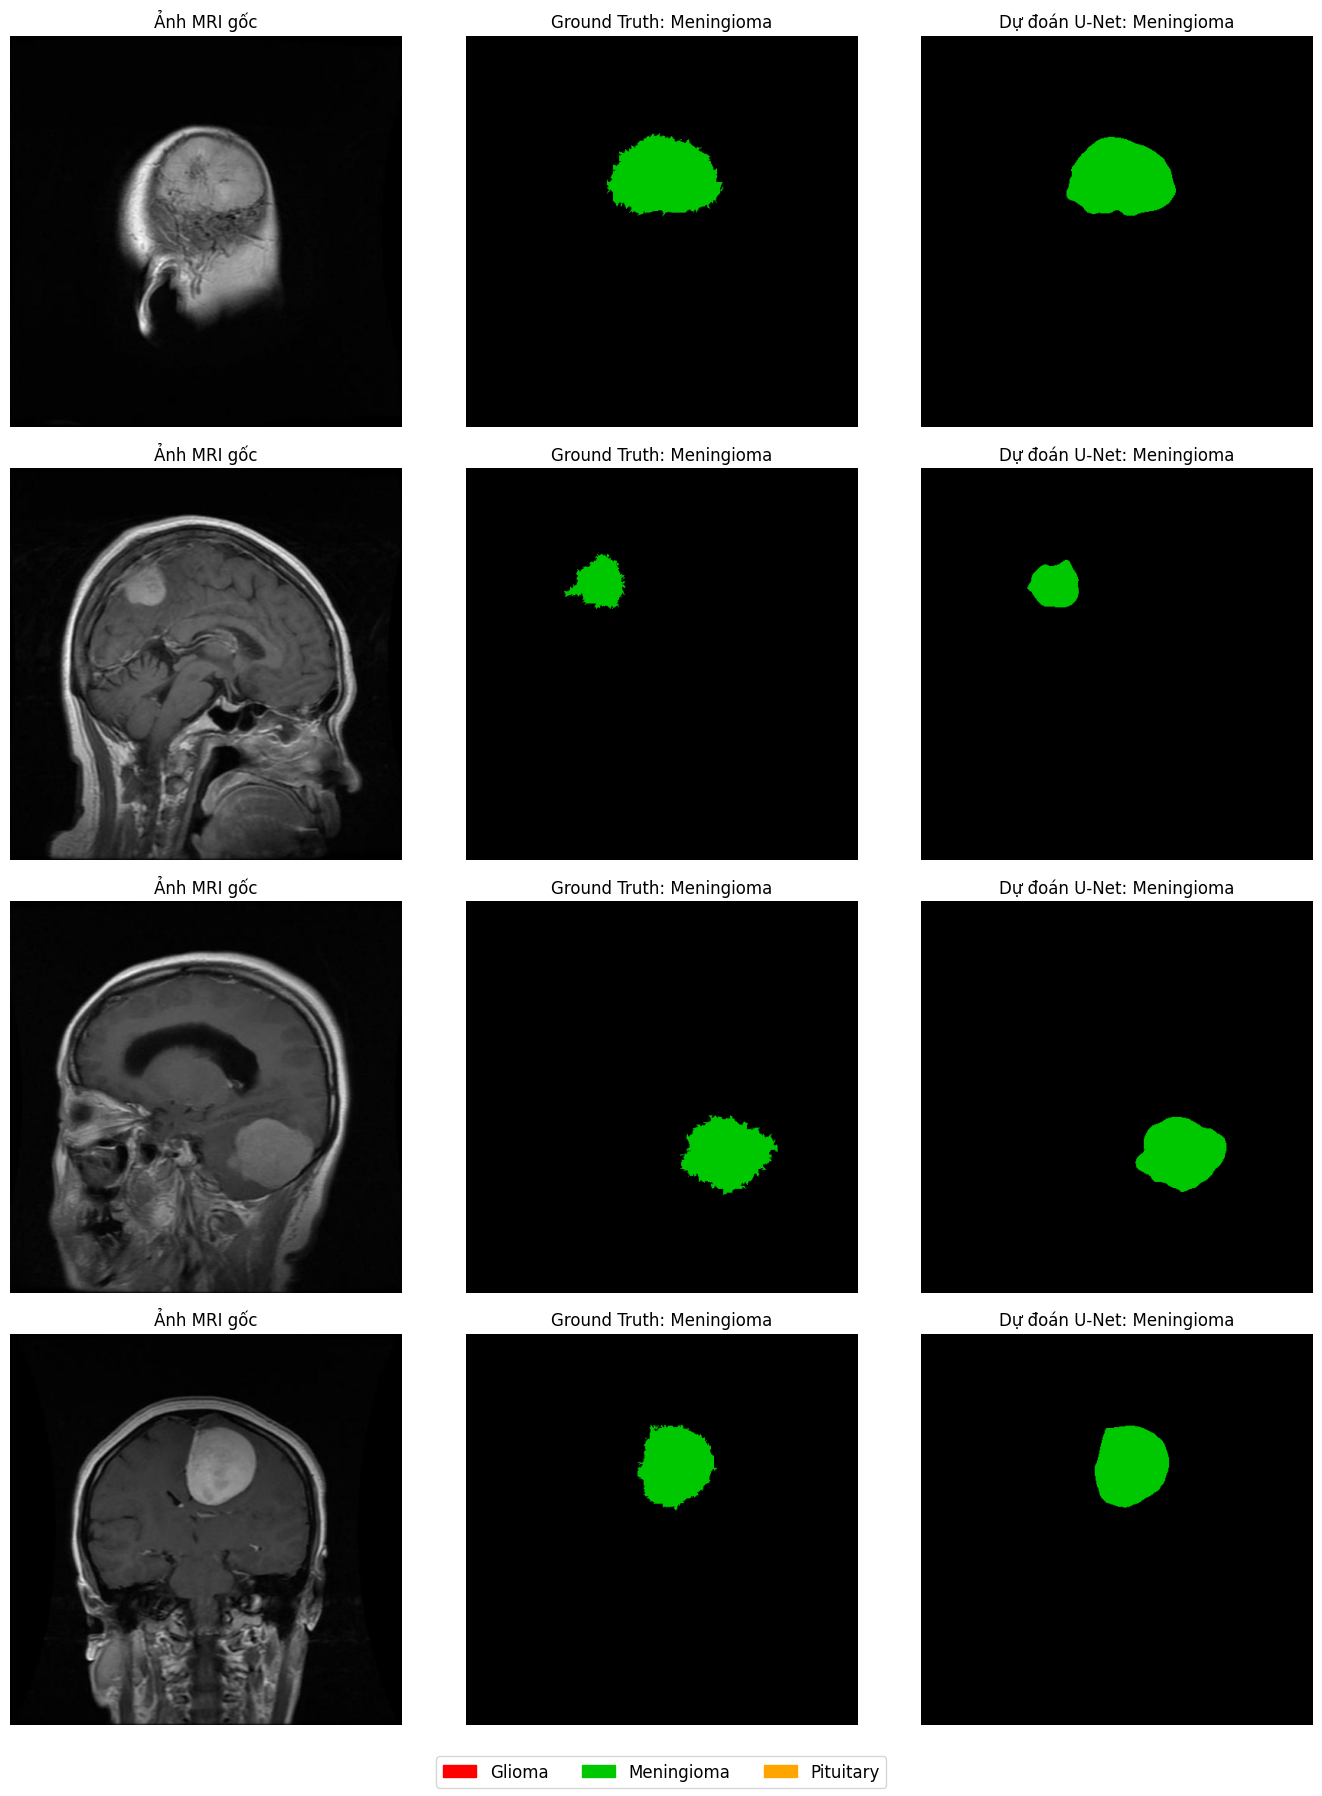

In [10]:
import random

raw_val_ds = BrainTumorDataset(
    img_dir  = DATA_DIR / 'images/val',
    mask_dir = DATA_DIR / 'masks/val',
    transform= A.Compose([A.Resize(IMG_SIZE, IMG_SIZE)])
)

model.eval()
sample_indices = random.sample(range(len(raw_val_ds)), 4)
fig, axes = plt.subplots(4, 3, figsize=(14, 18))

norm = A.Compose([A.Normalize(mean=(0.485,0.456,0.406), std=(0.229,0.224,0.225)), ToTensorV2()])

for row, idx in enumerate(sample_indices):
    img_raw, mask_raw = raw_val_ds[idx]
    img_np   = np.array(img_raw)
    mask_np  = mask_raw.cpu().numpy() if isinstance(mask_raw, torch.Tensor) else np.array(mask_raw)

    inp  = norm(image=img_np)['image'].unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        with torch.cuda.amp.autocast(enabled=(DEVICE.type == 'cuda')):
            pred_mask = torch.argmax(model(inp), dim=1).squeeze().cpu().numpy()

    gt_class  = CLASS_NAMES[int(mask_np.max())] if mask_np.max() > 0 else 'Background'
    pr_class  = CLASS_NAMES[int(pred_mask.max())] if pred_mask.max() > 0 else 'Background'

    axes[row][0].imshow(img_np);                 axes[row][0].set_title('Ảnh MRI gốc');         axes[row][0].axis('off')
    axes[row][1].imshow(mask_to_rgb(mask_np));   axes[row][1].set_title(f'Ground Truth: {gt_class}'); axes[row][1].axis('off')
    axes[row][2].imshow(mask_to_rgb(pred_mask)); axes[row][2].set_title(f'Dự đoán U-Net: {pr_class}'); axes[row][2].axis('off')

patches = [mpatches.Patch(color=np.array(c)/255, label=n)
           for n, c in zip(CLASS_NAMES[1:], [[255,0,0],[0,200,0],[255,165,0]])]
fig.legend(handles=patches, loc='lower center', ncol=3, fontsize=12)
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig(str(SAVE_DIR / 'predictions.png'), dpi=150)
plt.show()

## 11. 🏆 BẢNG ĐỐI SÁNH TOÀN DIỆN CẢ 3 MÔ HÌNH: YOLOv8 vs YOLO11 vs U-Net
Bảng so sánh tích hợp toàn bộ kết quả thực nghiệm của đồ án.

In [11]:
comparison = {
    'Tiêu chí đánh giá': [
        'Hướng tiếp cận',
        'Kiến trúc cốt lõi',
        'Số tham số (Params)',
        'Kích thước file trọng số',
        'Loại phân đoạn',
        'Metric chính',
        'Hiệu năng Glioma (U khó)',
        'Hiệu năng Meningioma',
        'Hiệu năng Pituitary',
        'HIỆU NĂNG TỔNG THỂ',
        'Tốc độ suy luận (GPU)'
    ],
    'YOLOv8s-seg': [
        'Top-down Detection + Mask',
        'YOLOv8 (C2f backbone)',
        '11.78 M',
        '22.75 MB',
        'Instance Segmentation',
        'Mask mAP50',
        '81.8% mAP50',
        '98.7% mAP50',
        '91.2% mAP50',
        '90.56% mAP50',
        '~6.4 ms / ảnh'
    ],
    'YOLO11s-seg': [
        'Top-down Detection + Mask',
        'YOLO11 (C3k2 + Attention)',
        '10.07 M (-14.5%)',
        '20.50 MB',
        'Instance Segmentation',
        'Mask mAP50',
        '83.0% mAP50 (+1.2%)',
        '98.4% mAP50',
        '90.5% mAP50',
        '90.64% mAP50',
        '~6.0 ms / ảnh'
    ],
    'Attention U-Net': [
        'Pixel-level Segmentation',
        'U-Net + scSE Attention',
        f'{params/1e6:.2f} M',
        '~20.5 MB',
        'Semantic Segmentation',
        'Dice Score / IoU',
        f"{np.mean(all_dice[0]):.2%} Dice",
        f"{np.mean(all_dice[1]):.2%} Dice",
        f"{np.mean(all_dice[2]):.2%} Dice",
        f"{mean_dice:.2%} Dice ({mean_iou:.2%} IoU)",
        '~12.0 ms / ảnh'
    ]
}

df_cmp = pd.DataFrame(comparison)
print('\n' + '='*65)
print('        BẢNG ĐỐI SÁNH HIỆU NĂNG 3 KIẾN TRÚC MÔ HÌNH')
print('='*65)
display(df_cmp)
df_cmp.to_csv(str(SAVE_DIR / 'full_3model_comparison.csv'), index=False, encoding='utf-8-sig')
print('\nĐã lưu bảng đối sánh tại:', SAVE_DIR / 'full_3model_comparison.csv')


        BẢNG ĐỐI SÁNH HIỆU NĂNG 3 KIẾN TRÚC MÔ HÌNH


,Tiêu chí đánh giá,YOLOv8s-seg,YOLO11s-seg,Attention U-Net
0,Hướng tiếp cận,Top-down Detection + Mask,Top-down Detection + Mask,Pixel-level Segmentation
1,Kiến trúc cốt lõi,YOLOv8 (C2f backbone),YOLO11 (C3k2 + Attention),U-Net + scSE Attention
2,Số tham số (Params),11.78 M,10.07 M (-14.5%),6.30 M
3,Kích thước file trọng số,22.75 MB,20.50 MB,~20.5 MB
4,Loại phân đoạn,Instance Segmentation,Instance Segmentation,Semantic Segmentation
5,Metric chính,Mask mAP50,Mask mAP50,Dice Score / IoU
6,Hiệu năng Glioma (U khó),81.8% mAP50,83.0% mAP50 (+1.2%),91.07% Dice
7,Hiệu năng Meningioma,98.7% mAP50,98.4% mAP50,95.41% Dice
8,Hiệu năng Pituitary,91.2% mAP50,90.5% mAP50,92.28% Dice
9,HIỆU NĂNG TỔNG THỂ,90.56% mAP50,90.64% mAP50,92.92% Dice (89.61% IoU)



Đã lưu bảng đối sánh tại: /kaggle/working/runs/unet_attention/full_3model_comparison.csv


## 12. Đóng gói & Tải file trọng số U-Net (`best_unet.pt`)

In [12]:
from IPython.display import FileLink
import shutil

final_path = WORKING_DIR / 'best_unet.pt'
shutil.copy2(BEST_PATH, final_path)
print(f'File trọng số U-Net: {final_path}')
print(f'Kích thước: {final_path.stat().st_size / 1024**2:.2f} MB')
FileLink(r'best_unet.pt')

File trọng số U-Net: /kaggle/working/best_unet.pt
Kích thước: 24.39 MB


/kaggle/working/best_unet.pt